In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Load the preprocessed and scaled patient data

file_path = "../outputs/processed_data/patient_features_scaled.csv"

df = pd.read_csv(file_path)

# Display dataset information

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (50000, 8)

First 5 Records:


,patient_id,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Seasonality
0,P000001,0.476281,0.108664,0.256826,-0.908192,-0.93317,-0.510987,0.626728
1,P000002,0.895072,-0.927572,0.014870,-0.908192,-0.93317,-0.510987,1.232359
2,P000003,-0.093747,0.945274,0.830264,2.336875,0.82465,1.439255,-0.341213
3,P000004,-0.974302,0.442257,0.547028,-0.908192,-0.93317,1.199281,0.220843
4,P000005,0.093481,-0.927572,0.472493,-0.908192,-0.93317,-0.510987,1.232359



Column Names:
['patient_id', 'Recency', 'Frequency', 'Monetary', 'Admission_Frequency', 'Average_LOS', 'Lab_Frequency', 'Seasonality']


In [3]:
# Select features for K-Means clustering

feature_columns = [
    'Recency',
    'Frequency',
    'Monetary',
    'Admission_Frequency',
    'Average_LOS',
    'Lab_Frequency',
    'Seasonality'
]

X = df[feature_columns]

print("Clustering Data Shape:", X.shape)

print("\nFeature Summary:")
display(X.describe())

Clustering Data Shape: (50000, 7)

Feature Summary:


,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Seasonality
count,5.000000e+04,5.000000e+04,5.000000e+04,5.000000e+04,5.000000e+04,5.000000e+04,5.000000e+04
mean,5.224976e-16,1.590195e-16,-5.300294e-16,4.732215e-17,7.451817e-17,3.949907e-16,-5.549339e-17
std,1.000010e+00,1.000010e+00,1.000010e+00,1.000010e+00,1.000010e+00,1.000010e+00,1.000010e+00
min,-3.189624e+00,-1.963809e+00,-2.629917e+00,-9.081920e-01,-9.331702e-01,-1.590046e+00,-2.432668e+00
25%,-5.823636e-01,-9.275724e-01,-3.408611e-02,-9.081920e-01,-9.331702e-01,-5.109868e-01,-4.060333e-01
50%,1.421674e-01,1.086638e-01,2.979707e-01,-9.081920e-01,-9.331702e-01,1.202222e-01,9.758730e-02
75%,7.841311e-01,7.148232e-01,5.631644e-01,4.893821e-01,9.613528e-01,5.680720e-01,5.183820e-01
max,1.290922e+00,1.981511e+00,1.023443e+00,2.336875e+00,2.024549e+00,1.994510e+00,1.232359e+00


In [4]:
# Apply Elbow Method to find the optimal number of clusters

wcss = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)

    wcss.append(kmeans.inertia_)

print("WCSS Values:")
for k, value in zip(range(2, 11), wcss):
    print(f"K = {k}: {value:.2f}")

WCSS Values:
K = 2: 251000.84
K = 3: 197044.41
K = 4: 164485.83
K = 5: 136501.80
K = 6: 117756.86
K = 7: 110723.69
K = 8: 105003.15
K = 9: 98860.38
K = 10: 93425.57


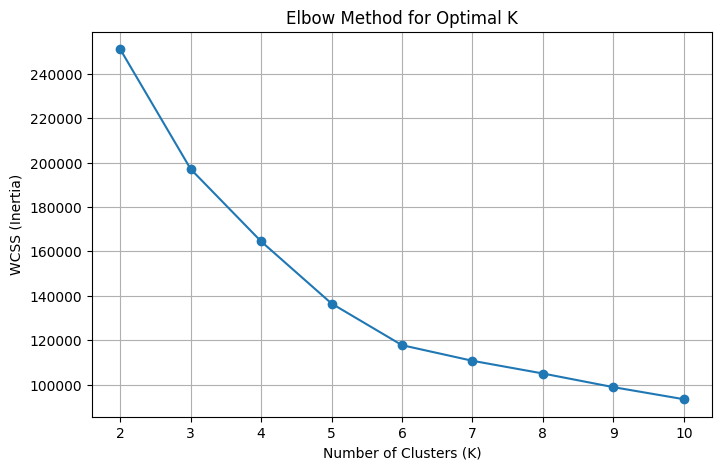

In [5]:
# Plot Elbow Method graph

plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), wcss, marker='o')

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [6]:
# Calculate Silhouette Scores for different K values

silhouette_scores = []

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X)

    score = silhouette_score(
        X,
        cluster_labels,
        sample_size=5000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.2813
K = 3, Silhouette Score = 0.3334
K = 4, Silhouette Score = 0.3498
K = 5, Silhouette Score = 0.3282
K = 6, Silhouette Score = 0.3032
K = 7, Silhouette Score = 0.2764
K = 8, Silhouette Score = 0.2625


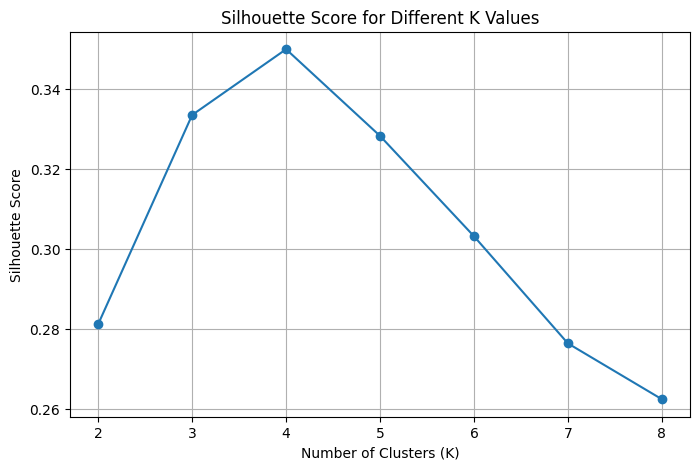

In [7]:
# Plot Silhouette Scores

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    silhouette_scores,
    marker='o'
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(True)

plt.show()

In [8]:
# Compare WCSS and Silhouette Scores

comparison = pd.DataFrame({
    "K": range(2, 9),
    "WCSS": wcss[:7],
    "Silhouette_Score": silhouette_scores
})

display(comparison.round(4))

# Identify K with the highest Silhouette Score

best_silhouette_k = comparison.loc[
    comparison["Silhouette_Score"].idxmax(), "K"
]

print("K with highest Silhouette Score:", best_silhouette_k)

,K,WCSS,Silhouette_Score
0,2,251000.8351,0.2813
1,3,197044.4123,0.3334
2,4,164485.8310,0.3498
3,5,136501.7989,0.3282
4,6,117756.8619,0.3032
5,7,110723.6880,0.2764
6,8,105003.1504,0.2625


K with highest Silhouette Score: 4


In [9]:
print("Cluster Selection Summary")
print("-------------------------")

print("Highest Silhouette Score K:", best_silhouette_k)

print("\nRemember:")
print("1. Check the elbow point in the WCSS graph.")
print("2. Check the Silhouette Score for cluster separation.")
print("3. Consider whether the resulting segments are useful.")

Cluster Selection Summary
-------------------------
Highest Silhouette Score K: 4

Remember:
1. Check the elbow point in the WCSS graph.
2. Check the Silhouette Score for cluster separation.
3. Consider whether the resulting segments are useful.
